<center><h1>Do_Mimi_HW2</h1></center>
<br>
<br>

Name: Mimi Do
<br>
Github Username: mkd222
<br>
USC ID: 8125-6556-10

## 1. Combined Cycle Power Plant Data Set

### (a) Download Data

Package imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler

Get the Cycle Power Plant Data Set

In [2]:
df = pd.read_excel("../data/Folds5x2_pp.xlsx", sheet_name = 0)

df.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


### (b) Exploring the data

#### i. rows and columns

In [3]:
df.shape

(9568, 5)

Rows: 9568     
Columns: 5    
Each row represents a data point that is the hourly average ambient variables observed. The columns represent Temperature (AT), Ambient Pressure (AP),
Relative Humidity (RH), Exhaust Vacuum (V), and Electrical Energy Output (EP).

#### ii. pairwise scatterplots of all the varianbles

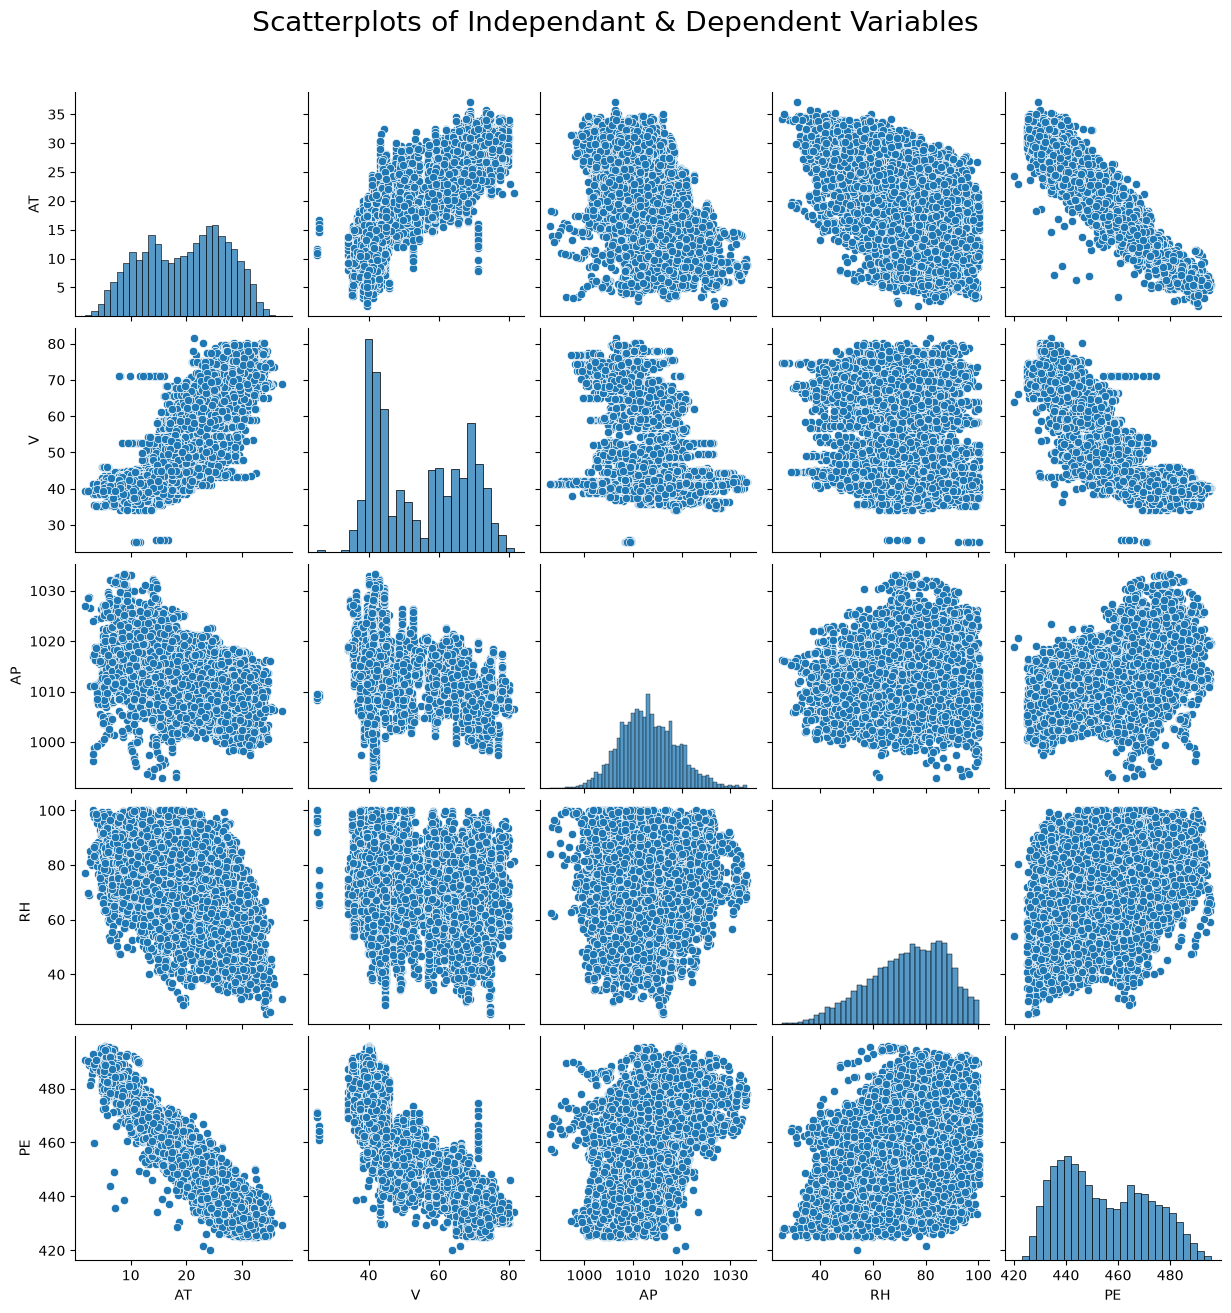

In [4]:
scatterplots = sns.pairplot(df)

scatterplots.figure.suptitle("Scatterplots of Independant & Dependent Variables", y = 1.05, fontsize = 20)

plt.show()

-   PE and AT appears to have a strong negative relationship. As temperature increases, energy output decreases.
-   PE and V appears to have a somewhat negative relationship. As exhaust vacuum increases, energy output seems to generally decrease. Although there are several outliers.
-   PE and AP appears to have a weak positive relationship. As ambient pressure increases, energy output generally increases as well.
-   PE and RH appears to have the weakest positive relationship. as relative humidity increases, energy output somewhat increases.
-   AT and V appears to have a positive relationship. As temperature increases, exhaust vaccum increases.

#### iii. mean, the median, range, first and third quartiles, and interquartile ranges

In [5]:
summary = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median(),
    "Range": df.max() - df.min(),
    "Q1": df.quantile(0.25),
    "Q3": df.quantile(0.75),
    "IQR": df.quantile(0.75) - df.quantile(0.25)
    }).round(2)

summary

,Mean,Median,Range,Q1,Q3,IQR
AT,19.65,20.34,35.30,13.51,25.72,12.21
V,54.31,52.08,56.20,41.74,66.54,24.80
AP,1013.26,1012.94,40.41,1009.10,1017.26,8.16
RH,73.31,74.97,74.60,63.33,84.83,21.50
PE,454.37,451.55,75.50,439.75,468.43,28.68


### (c) Simple Linear Regression

In [6]:
X = sm.add_constant(df["AT"])           # sm automatically assumes b = 0 without add_constant
at_rmodel = sm.OLS(df["PE"], X).fit()

X = sm.add_constant(df["V"])
v_rmodel = sm.OLS(df["PE"], X).fit()

X = sm.add_constant(df["AP"])
ap_rmodel = sm.OLS(df["PE"], X).fit()

X = sm.add_constant(df["RH"])
rh_rmodel = sm.OLS(df["PE"], X).fit()

print(at_rmodel.summary())
print(v_rmodel.summary())
print(ap_rmodel.summary())
print(rh_rmodel.summary())


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                 8.510e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:56:56   Log-Likelihood:                -29756.
No. Observations:                9568   AIC:                         5.952e+04
Df Residuals:                    9566   BIC:                         5.953e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        497.0341      0.156   3177.280      0.0

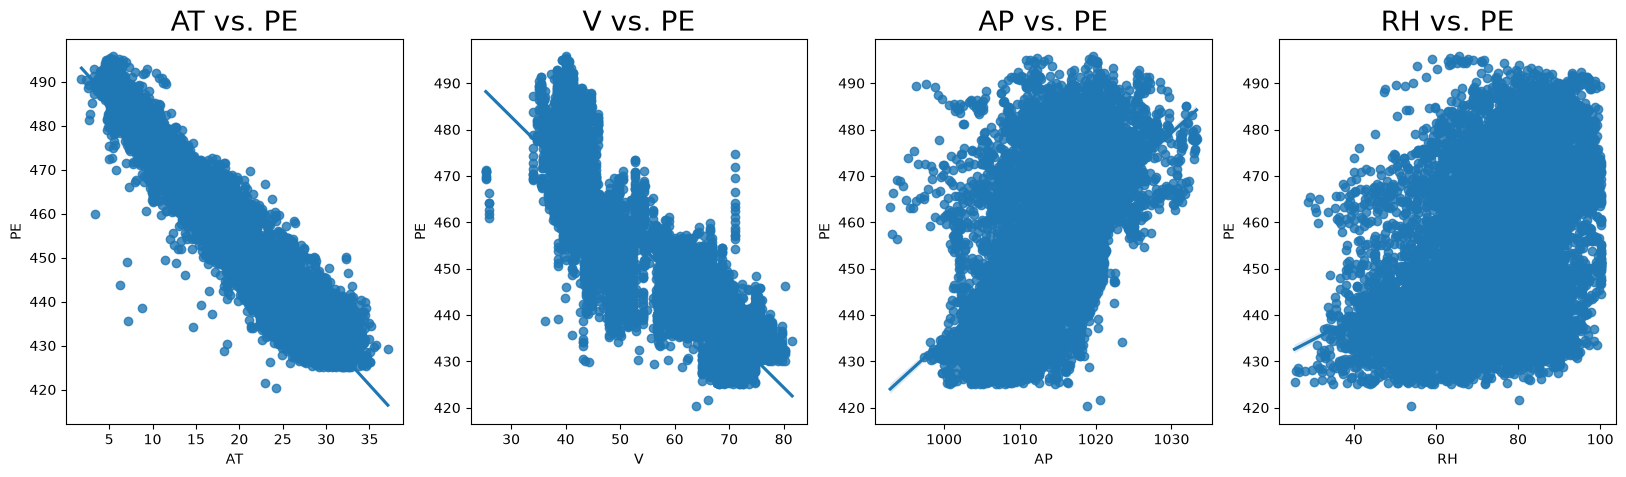

In [7]:
fig, axs = plt.subplots(1, 4, figsize = (20, 5))

sns.regplot(data = df, x = "AT", y = "PE", ax = axs[0])
axs[0].set_title("AT vs. PE", fontsize = 20)

sns.regplot(data = df, x = "V", y = "PE", ax = axs[1])
axs[1].set_title("V vs. PE", fontsize = 20)

sns.regplot(data = df, x = "AP", y = "PE", ax = axs[2])
axs[2].set_title("AP vs. PE", fontsize = 20)

sns.regplot(data = df, x = "RH", y = "PE", ax = axs[3])
axs[3].set_title("RH vs. PE", fontsize = 20)

plt.show()


-   All predictors appear to be statistically significant because every model shows p-values < 0.05.
-   The data points seem to generally follow the regression line although, some more than others. 
-   There are several outliers in each model that dont't appear to follow the regression line. However, further analysis involving different factors would need to be conducted in order to determine whether removing them would be the best course of action.

### (d) Multiple Regression

In [8]:
X = sm.add_constant(df[["AT", "V", "AP", "RH"]])          
all_rmodels = sm.OLS(df["PE"], X).fit()

print(all_rmodels.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:56:58   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        454.6093      9.749     46.634      0.0

-   We can reject the null hypothesis for all predictors because all p-values < 0.05

### (e) 1c Compare to 1d

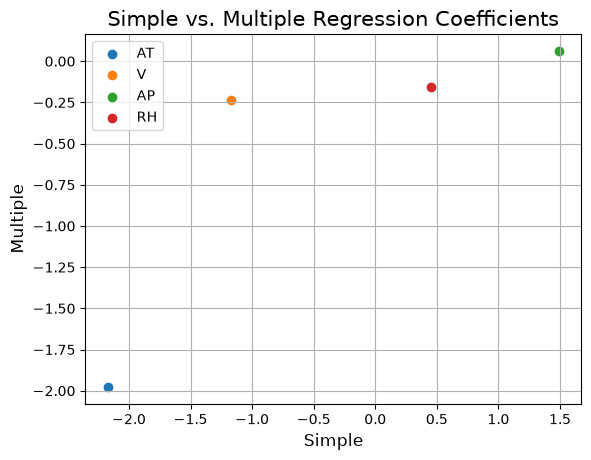

In [9]:
simple_coefficient = [
    at_rmodel.params["AT"],             # remove const
    v_rmodel.params["V"],
    ap_rmodel.params["AP"],
    rh_rmodel.params["RH"]
]

multiple_coefficient = [
    all_rmodels.params["AT"],
    all_rmodels.params["V"],
    all_rmodels.params["AP"],
    all_rmodels.params["RH"]
]

plt.scatter(simple_coefficient[0], multiple_coefficient[0], label = "AT")
plt.scatter(simple_coefficient[1], multiple_coefficient[1], label = "V")
plt.scatter(simple_coefficient[2], multiple_coefficient[2], label = "AP")
plt.scatter(simple_coefficient[3], multiple_coefficient[3], label = "RH")

plt.xlabel("Simple", fontsize = 12)
plt.ylabel("Multiple", fontsize = 12)
plt.title("Simple vs. Multiple Regression Coefficients", fontsize = 15)
plt.grid()
plt.legend()

plt.show()

### (f) Nonlinear Association

In [10]:
poly = PolynomialFeatures(degree = 3)

X = poly.fit_transform(df[["AT"]])
at_poly = sm.OLS(df["PE"], X). fit()

X = poly.fit_transform(df[["V"]])
v_poly = sm.OLS(df["PE"], X). fit()

X = poly.fit_transform(df[["AP"]])
ap_poly = sm.OLS(df["PE"], X). fit()

X = poly.fit_transform(df[["RH"]])
rh_poly = sm.OLS(df["PE"], X). fit()

print(at_poly.summary())
print(v_poly.summary())
print(ap_poly.summary())
print(rh_poly.summary())


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                 3.299e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:56:58   Log-Likelihood:                -29101.
No. Observations:                9568   AIC:                         5.821e+04
Df Residuals:                    9564   BIC:                         5.824e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        492.7281      0.673    732.248      0.0

-   AT and PE appear to have a nonlinear association because $x^2$ and $x^3$ have p-values < 0.05
-   V and PE appear to have a nonlinear association. $x^2$ shows to be not statistically significant because 0.768 > 0.05. $x^3$ is statistically significant because 0.014 < 0.05
-   AP and PE appear to have a nonlinear association because $x^2$ and $x^3$ have p-values < 0.05
-   RH and PE appear to have a nonlinear association because $x^2$ and $x^3$ have p-values < 0.05

### (g) Interactions of Predictors

In [11]:
interaction_model = sm.formula.ols("PE ~ (AT + V + AP + RH)**2", data = df).fit()      # ~ = predicted by

print(interaction_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:56:58   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.0

-   There is evidence of interaction between the predictors
-   AT:AP and V:RH are not statistically significant because their p-values > 0.05
-   AT:V, AT:RH, V:AP, and AP:RH are statistically significant because their p-values < 0.05 

### (h) Improvement

In [12]:
train, test = train_test_split(df, train_size = 0.70, random_state = 1)

reg_model = sm.formula.ols("PE ~ AT + V + AP + RH", data = train).fit() 

reg_train_predict = reg_model.predict(train)
reg_test_predict = reg_model.predict(test)

reg_train_mse = mean_squared_error(train["PE"], reg_train_predict)
reg_test_mse = mean_squared_error(test["PE"], reg_test_predict)

In [13]:
# model w/ all interactions and quadratics
all2_rmodels = sm.formula.ols("PE ~ (AT + V + AP + RH)**2 + I(AT**2) + I(V**2) + I(AP**2) + I(RH**2)", data = train).fit()

print(all2_rmodels.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     7181.
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:56:58   Log-Likelihood:                -19192.
No. Observations:                6697   AIC:                         3.841e+04
Df Residuals:                    6682   BIC:                         3.852e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -8171.8080   1416.708     -5.768      0.0

In [14]:
# improved model with AT:AP, V:AP, V:RH, and V^2 removed 
improved_model = sm.formula.ols("PE ~ AT + V + AP + RH + AT:V + AT:RH + AP:RH + I(AT**2) + I(AP**2) + I(RH**2)", data = train).fit()

print(improved_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.937
Method:                 Least Squares   F-statistic:                 1.004e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:56:58   Log-Likelihood:                -19198.
No. Observations:                6697   AIC:                         3.842e+04
Df Residuals:                    6686   BIC:                         3.849e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.052e+04   1079.936     -9.738      0.0

-   Variables removed: AT:AP, V:AP, V:RH, and $V^2$ because p-value > 0.05

In [15]:
improved_train_predict = improved_model.predict(train)
improved_test_predict = improved_model.predict(test)

improved_train_mse = mean_squared_error(train["PE"], improved_train_predict)
improved_test_mse = mean_squared_error(test["PE"], improved_test_predict)

In [16]:
all_mse = pd.DataFrame({
    "Model": ["Regression", "Improved"],
    "Train MSE": [reg_train_mse, improved_train_mse],
    "Test MSE": [reg_test_mse, improved_test_mse]
    })

all_mse

,Model,Train MSE,Test MSE
0,Regression,20.766120,20.777478
1,Improved,18.093236,18.263588


### (i) KNN

In [17]:
features = ["AT", "V", "AP", "RH"]

X_train = train[features]
X_test = test[features]

y_train = train["PE"]
y_test = test["PE"]

k_values = range(1, 101)


# raw features
raw_train_mse = []
raw_test_mse = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors = k)

    knn.fit(X_train, y_train)

    train_predict = knn.predict(X_train)
    test_predict = knn.predict(X_test)

    raw_train_mse.append(mean_squared_error(y_train, train_predict))
    raw_test_mse.append(mean_squared_error(y_test, test_predict))

best_raw_k = np.argmin(raw_test_mse) + 1

print(best_raw_k)

5


In [18]:
# normalized features
normalize = MinMaxScaler()

X_train_normalize = normalize.fit_transform(X_train)
X_test_normalize = normalize.transform(X_test)

normalize_train_mse = []
normalize_test_mse = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors = k)

    knn.fit(X_train_normalize, y_train)

    train_predict = knn.predict(X_train_normalize)
    test_predict = knn.predict(X_test_normalize)

    normalize_train_mse.append(mean_squared_error(y_train, train_predict))
    normalize_test_mse.append(mean_squared_error(y_test, test_predict))

best_normalize_k = np.argmin(normalize_test_mse) + 1

print(best_normalize_k)

5


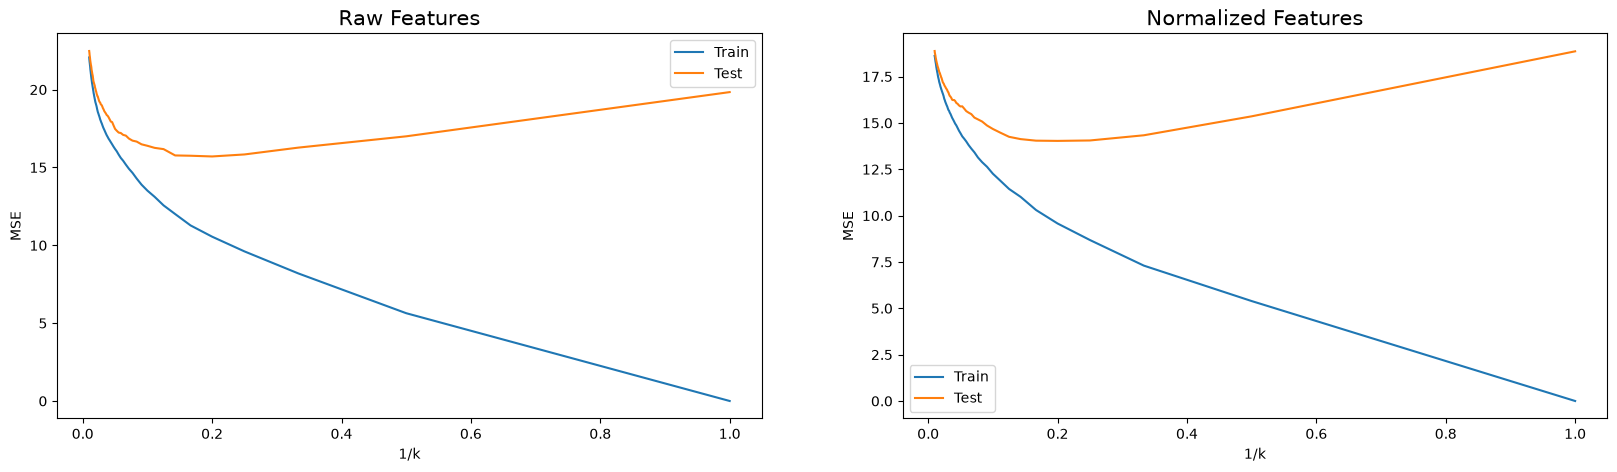

In [19]:
inverse_k = 1 / np.array(list(k_values))

fig, plots = plt.subplots(1, 2, figsize = (20, 5))

plots[0].plot(inverse_k, raw_train_mse, label = "Train")
plots[0].plot(inverse_k, raw_test_mse, label = "Test")
plots[0].set_title("Raw Features", fontsize = 15)
plots[0].set_xlabel("1/k")
plots[0].set_ylabel("MSE")
plots[0].legend()

plots[1].plot(inverse_k, normalize_train_mse, label = "Train")
plots[1].plot(inverse_k, normalize_test_mse, label = "Test")
plots[1].set_title("Normalized Features", fontsize = 15)
plots[1].set_xlabel("1/k")
plots[1].set_ylabel("MSE")
plots[1].legend()

plt.show()

### (j ) Compare KNN and Linear

In [20]:
print("Best Raw Test MSE =", min(raw_test_mse))
print("Best Normalized Test MSE =", min(normalize_test_mse))
print("Improved Model Test MSE =", improved_test_mse)

Best Raw Test MSE = 15.704821203761764
Best Normalized Test MSE = 14.030553676071062
Improved Model Test MSE = 18.263588112325383


-   KNN performed better than the linear regression model because both the raw and normalized test MSE are less than the improved linear regression model MSE

## 2. ISLR: 2.4.1

### (a) The sample size n is extremely large, and the number of predictors p is small.

-   Better than inflexible method
-   There is enough data to learn complex patterns without overfitting

### (b) The number of predictors p is extremely large, and the number of observations n is small.

-   Worse than inflexible method
-   It will most likely overfit the data

### (c) The relationship between the predictors and response is highly non-linear.

-   Better than inflexible method
-   It is designed to capture non-linear relationships

### (d) The variance of the error terms, i.e. $σ^2$ = Var(ε), is extremely high.

-   Worse than inflexible method
-   Since the data is noisy, it could react too much to random variation instead of the true pattern

## 3. ISLR: 2.4.7

### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

-   Obs 1 = 3
-   Obs 2 = 2
-   Obs 3 = 3.16
-   Obs 4 = 2.24
-   Obs 5 = 1.41
-   Obs 6 = 1.73

### (b) What is our prediction with K = 1? Why?

-   Green, because that is the nearest neighbor

### (c) What is our prediction with K = 3? Why?

-   Red, because that is the majority out of 3 nearest neighbors

### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?

-   A small K would be better because it is more flexible. It can follow complicated decision boundries better